<center><h1>Du_Isabelle_HW7</h1></center>

Name: Isabelle Du
<br>
Github Username: yxd-1213
<br>
USC ID: 5984907579

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

Import packages

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

### (a) Download the Anuran Calls (MFCCs) Data Set

In [2]:
# Load the dataset
df = pd.read_csv("anuran+calls+mfccs/Frogs_MFCCs.csv")

# Features and labels
X = df.drop(columns=["Family", "Genus", "Species", "RecordID"])
y = df[["Family", "Genus", "Species"]]

# Random 70% training / 30% test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42
)

print("Dataset shape:", df.shape)
print("Training set:", X_train.shape, y_train.shape)
print("Test set:", X_test.shape, y_test.shape)

df.head()

Dataset shape: (7195, 26)
Training set: (5036, 22) (5036, 3)
Test set: (2159, 22) (2159, 3)


,MFCCs_ 1,MFCCs_ 2,MFCCs_ 3,MFCCs_ 4,MFCCs_ 5,MFCCs_ 6,MFCCs_ 7,MFCCs_ 8,MFCCs_ 9,MFCCs_10,...,MFCCs_17,MFCCs_18,MFCCs_19,MFCCs_20,MFCCs_21,MFCCs_22,Family,Genus,Species,RecordID
0,1.0,0.152936,-0.105586,0.200722,0.317201,0.260764,0.100945,-0.150063,-0.171128,0.124676,...,-0.108351,-0.077623,-0.009568,0.057684,0.118680,0.014038,Leptodactylidae,Adenomera,AdenomeraAndre,1
1,1.0,0.171534,-0.098975,0.268425,0.338672,0.268353,0.060835,-0.222475,-0.207693,0.170883,...,-0.090974,-0.056510,-0.035303,0.020140,0.082263,0.029056,Leptodactylidae,Adenomera,AdenomeraAndre,1
2,1.0,0.152317,-0.082973,0.287128,0.276014,0.189867,0.008714,-0.242234,-0.219153,0.232538,...,-0.050691,-0.023590,-0.066722,-0.025083,0.099108,0.077162,Leptodactylidae,Adenomera,AdenomeraAndre,1
3,1.0,0.224392,0.118985,0.329432,0.372088,0.361005,0.015501,-0.194347,-0.098181,0.270375,...,-0.136009,-0.177037,-0.130498,-0.054766,-0.018691,0.023954,Leptodactylidae,Adenomera,AdenomeraAndre,1
4,1.0,0.087817,-0.068345,0.306967,0.330923,0.249144,0.006884,-0.265423,-0.172700,0.266434,...,-0.048885,-0.053074,-0.088550,-0.031346,0.108610,0.079244,Leptodactylidae,Adenomera,AdenomeraAndre,1


### (b) Train a classifier for each label

#### (i) Research

**Exact Match:**  
Exact match checks whether all three predicted labels for an observation are correct. A prediction is counted as correct only if Family, Genus, and Species all match the true labels. Therefore, it is a strict measure.

**Hamming Loss:**  
Hamming loss measures the fraction of individual labels that are predicted incorrectly.

$$
\text{Hamming Loss}
=
\frac{1}{NL}
\sum_{i=1}^{N}
\sum_{j=1}^{L}
I(\hat{y}_{ij}\neq y_{ij})
$$

where $N$ is the number of observations and $L=3$ is the number of labels.

**Hamming Score:**  
The Hamming score can be calculated as

$$
\text{Hamming Score}=1-\text{Hamming Loss}.
$$

A higher exact match or Hamming score is better, while a lower Hamming loss is better.

#### (ii) Train a SVM for each of the labels

In [3]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, hamming_loss

C_vals = [0.1, 1, 10, 100]
gamma_vals = [0.01, 0.1, 1]

preds = pd.DataFrame(index=y_test.index)
results = {}

for label in ["Family", "Genus", "Species"]:
    pipe = Pipeline([
        ("scale", StandardScaler()),
        ("clf", OneVsRestClassifier(SVC(kernel="rbf")))
    ])

    grid = GridSearchCV(
        pipe,
        {
            "clf__estimator__C": C_vals,
            "clf__estimator__gamma": gamma_vals
        },
        cv=10,
        scoring="accuracy",
        n_jobs=-1
    )

    grid.fit(X_train, y_train[label])
    preds[label] = grid.predict(X_test)

    results[label] = {
        "Best C": grid.best_params_["clf__estimator__C"],
        "Best gamma": grid.best_params_["clf__estimator__gamma"],
        "Test accuracy": accuracy_score(y_test[label], preds[label])
    }

pd.DataFrame(results).T

,Best C,Best gamma,Test accuracy
Family,10.0,0.1,0.993516
Genus,10.0,0.1,0.988421
Species,10.0,0.1,0.987957


In [5]:
exact_match = np.mean((preds.values == y_test.values).all(axis=1))
h_loss = np.mean(preds.values != y_test.values)

print("Exact Match:", round(exact_match, 4))
print("Hamming Loss:", round(h_loss, 4))
print("Hamming Score:", round(1 - h_loss, 4))

Exact Match: 0.9866
Hamming Loss: 0.01
Hamming Score: 0.99


#### (iii) Repeat 1(b)ii with L1-penalized SVMs

In [7]:
from sklearn.svm import LinearSVC

C_vals = [0.01, 0.1, 1, 10, 100]

preds_l1 = pd.DataFrame(index=y_test.index)
results_l1 = {}

for label in ["Family", "Genus", "Species"]:
    pipe = Pipeline([
        ("scale", StandardScaler()),
        ("clf", OneVsRestClassifier(
            LinearSVC(penalty="l1", dual=False, max_iter=100000)
        ))
    ])

    grid = GridSearchCV(
        pipe,
        {"clf__estimator__C": C_vals},
        cv=10,
        scoring="accuracy",
        n_jobs=-1
    )

    grid.fit(X_train, y_train[label])
    preds_l1[label] = grid.predict(X_test)

    results_l1[label] = {
        "Best C": grid.best_params_["clf__estimator__C"],
        "Test accuracy": accuracy_score(y_test[label], preds_l1[label])
    }

display(pd.DataFrame(results_l1).T)

exact_l1 = np.mean((preds_l1.values == y_test.values).all(axis=1))
loss_l1 = np.mean(preds_l1.values != y_test.values)

print("Exact Match:", round(exact_l1, 4))
print("Hamming Loss:", round(loss_l1, 4))
print("Hamming Score:", round(1 - loss_l1, 4))

,Best C,Test accuracy
Family,1.0,0.928671
Genus,10.0,0.941640
Species,10.0,0.959240


Exact Match: 0.9129
Hamming Loss: 0.0568
Hamming Score: 0.9432


#### (iv) Repeat 1(b)iii by using SMOTE or any other method for imbalance

In [8]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

preds_smote = pd.DataFrame(index=y_test.index)
results_smote = {}

for label in ["Family", "Genus", "Species"]:
    pipe = ImbPipeline([
        ("scale", StandardScaler()),
        ("smote", SMOTE(random_state=42)),
        ("clf", OneVsRestClassifier(
            LinearSVC(penalty="l1", dual=False, max_iter=100000)
        ))
    ])

    grid = GridSearchCV(
        pipe,
        {"clf__estimator__C": C_vals},
        cv=10,
        scoring="accuracy",
        n_jobs=-1
    )

    grid.fit(X_train, y_train[label])
    preds_smote[label] = grid.predict(X_test)

    results_smote[label] = {
        "Best C": grid.best_params_["clf__estimator__C"],
        "Test accuracy": accuracy_score(
            y_test[label], preds_smote[label]
        )
    }

display(pd.DataFrame(results_smote).T)

exact_smote = np.mean(
    (preds_smote.values == y_test.values).all(axis=1)
)
loss_smote = np.mean(
    preds_smote.values != y_test.values
)

print("Exact Match:", round(exact_smote, 4))
print("Hamming Loss:", round(loss_smote, 4))
print("Hamming Score:", round(1 - loss_smote, 4))

,Best C,Test accuracy
Family,1.0,0.908291
Genus,10.0,0.901806
Species,1.0,0.957388


Exact Match: 0.8518
Hamming Loss: 0.0775
Hamming Score: 0.9225


Using SMOTE did not improve the L1-SVM models in this case. The exact match decreased from 0.9129 to 0.8518, while the Hamming loss increased from 0.0568 to 0.0775. Therefore, the original L1-SVM without SMOTE performed better overall.

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

### (a) Use k-means clustering

In [9]:
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score

# Use the whole dataset
X_all = df.drop(columns=["Family", "Genus", "Species", "RecordID"])

ch_scores = []

for k in range(2, 51):
    km = KMeans(n_clusters=k, random_state=1, n_init=10)
    clusters = km.fit_predict(X_all)
    ch_scores.append(calinski_harabasz_score(X_all, clusters))

best_k = np.argmax(ch_scores) + 2

print("Best k:", best_k)

Best k: 2


### (b) Determine which family is the majority

In [10]:
# Fit K-means using the selected k
km = KMeans(n_clusters=best_k, random_state=1, n_init=10)
clusters = km.fit_predict(X_all)

# Add cluster labels to the true labels
cluster_df = df[["Family", "Genus", "Species"]].copy()
cluster_df["Cluster"] = clusters

# Majority label in each cluster
majority_labels = cluster_df.groupby("Cluster")[
    ["Family", "Genus", "Species"]
].agg(lambda x: x.mode().iloc[0])

majority_labels

,Family,Genus,Species
Cluster,,,
0,Leptodactylidae,Adenomera,AdenomeraHylaedactylus
1,Hylidae,Hypsiboas,HypsiboasCordobae


### (c) Calculate the average Hamming distance, Hamming score, and Hamming loss

In [11]:
# Assign majority labels to each observation
pred_labels = majority_labels.loc[clusters].reset_index(drop=True)
true_labels = df[["Family", "Genus", "Species"]].reset_index(drop=True)

# Number of incorrect labels for each observation
distances = (pred_labels.values != true_labels.values).sum(axis=1)

avg_distance = distances.mean()
h_loss = avg_distance / 3
h_score = 1 - h_loss

print("Average Hamming Distance:", round(avg_distance, 4))
print("Hamming Loss:", round(h_loss, 4))
print("Hamming Score:", round(h_score, 4))

Average Hamming Distance: 0.8956
Hamming Loss: 0.2985
Hamming Score: 0.7015


In [12]:
mc_results = []

for r in range(50):
    # choose best k using CH score
    scores = []
    for k in range(2, 51):
        labels = KMeans(
            n_clusters=k, random_state=r, n_init=1
        ).fit_predict(X_all)

        scores.append(
            calinski_harabasz_score(X_all, labels)
        )

    k_best = np.argmax(scores) + 2

    # fit K-means using best k
    clusters_r = KMeans(
        n_clusters=k_best, random_state=r, n_init=1
    ).fit_predict(X_all)

    temp = df[["Family", "Genus", "Species"]].copy()
    temp["Cluster"] = clusters_r

    majority = temp.groupby("Cluster")[
        ["Family", "Genus", "Species"]
    ].agg(lambda x: x.mode().iloc[0])

    pred = majority.loc[clusters_r].reset_index(drop=True)
    true = df[["Family", "Genus", "Species"]].reset_index(drop=True)

    distance = (pred.values != true.values).sum(axis=1).mean()

    mc_results.append([k_best, distance, distance / 3, 1 - distance / 3])

mc = pd.DataFrame(
    mc_results,
    columns=["k", "Hamming Distance", "Hamming Loss", "Hamming Score"]
)

print("Mean:")
print(mc.mean().round(4))

print("\nStandard Deviation:")
print(mc.std().round(4))

Mean:
k                   2.0000
Hamming Distance    0.8956
Hamming Loss        0.2985
Hamming Score       0.7015
dtype: float64

Standard Deviation:
k                   0.0
Hamming Distance    0.0
Hamming Loss        0.0
Hamming Score       0.0
dtype: float64


The 50 Monte Carlo runs produced the same optimal $k=2$ and the same Hamming distance, so the standard deviation is 0.

## 3. ISLR 12.6.2

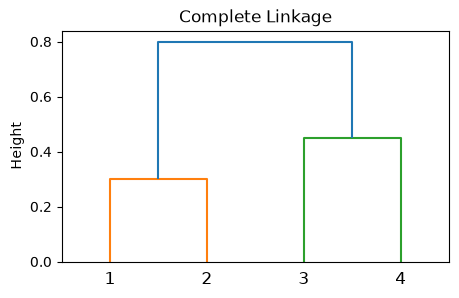

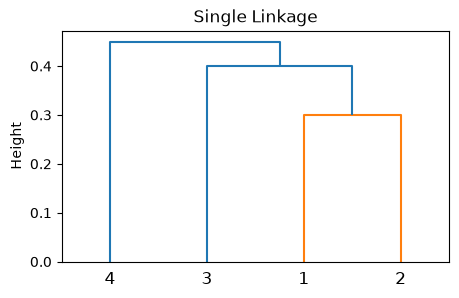

In [13]:
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform
import matplotlib.pyplot as plt

D = np.array([
    [0,   .3,  .4,  .7],
    [.3,  0,   .5,  .8],
    [.4,  .5,  0,   .45],
    [.7,  .8,  .45, 0]
])

d = squareform(D)

for method in ["complete", "single"]:
    Z = linkage(d, method=method)
    plt.figure(figsize=(5, 3))
    dendrogram(Z, labels=["1", "2", "3", "4"])
    plt.title(f"{method.capitalize()} Linkage")
    plt.ylabel("Height")
    plt.show()

**(a) Complete linkage**

Observations 1 and 2 are first joined at height 0.30. Observations 3 and 4 are then joined at height 0.45. Finally, the two clusters $\{1,2\}$ and $\{3,4\}$ are joined at height 0.80.

**(b) Single linkage**

Observations 1 and 2 are first joined at height 0.30. Observation 3 joins the cluster $\{1,2\}$ at height 0.40. Observation 4 then joins at height 0.45.

**(c)** Cutting the complete-linkage dendrogram to obtain two clusters gives

$$
\{1,2\}, \qquad \{3,4\}.
$$

**(d)** Cutting the single-linkage dendrogram to obtain two clusters gives

$$
\{1,2,3\}, \qquad \{4\}.
$$

**(e)** An equivalent complete-linkage dendrogram can be obtained by swapping the positions of leaves within a fusion. For example, the leaf order can be changed from $1,2,3,4$ to $2,1,4,3$ while keeping the same fusion heights $0.30$, $0.45$, and $0.80$.